# Figure 3 - Figure Code

Processing 68 patients...


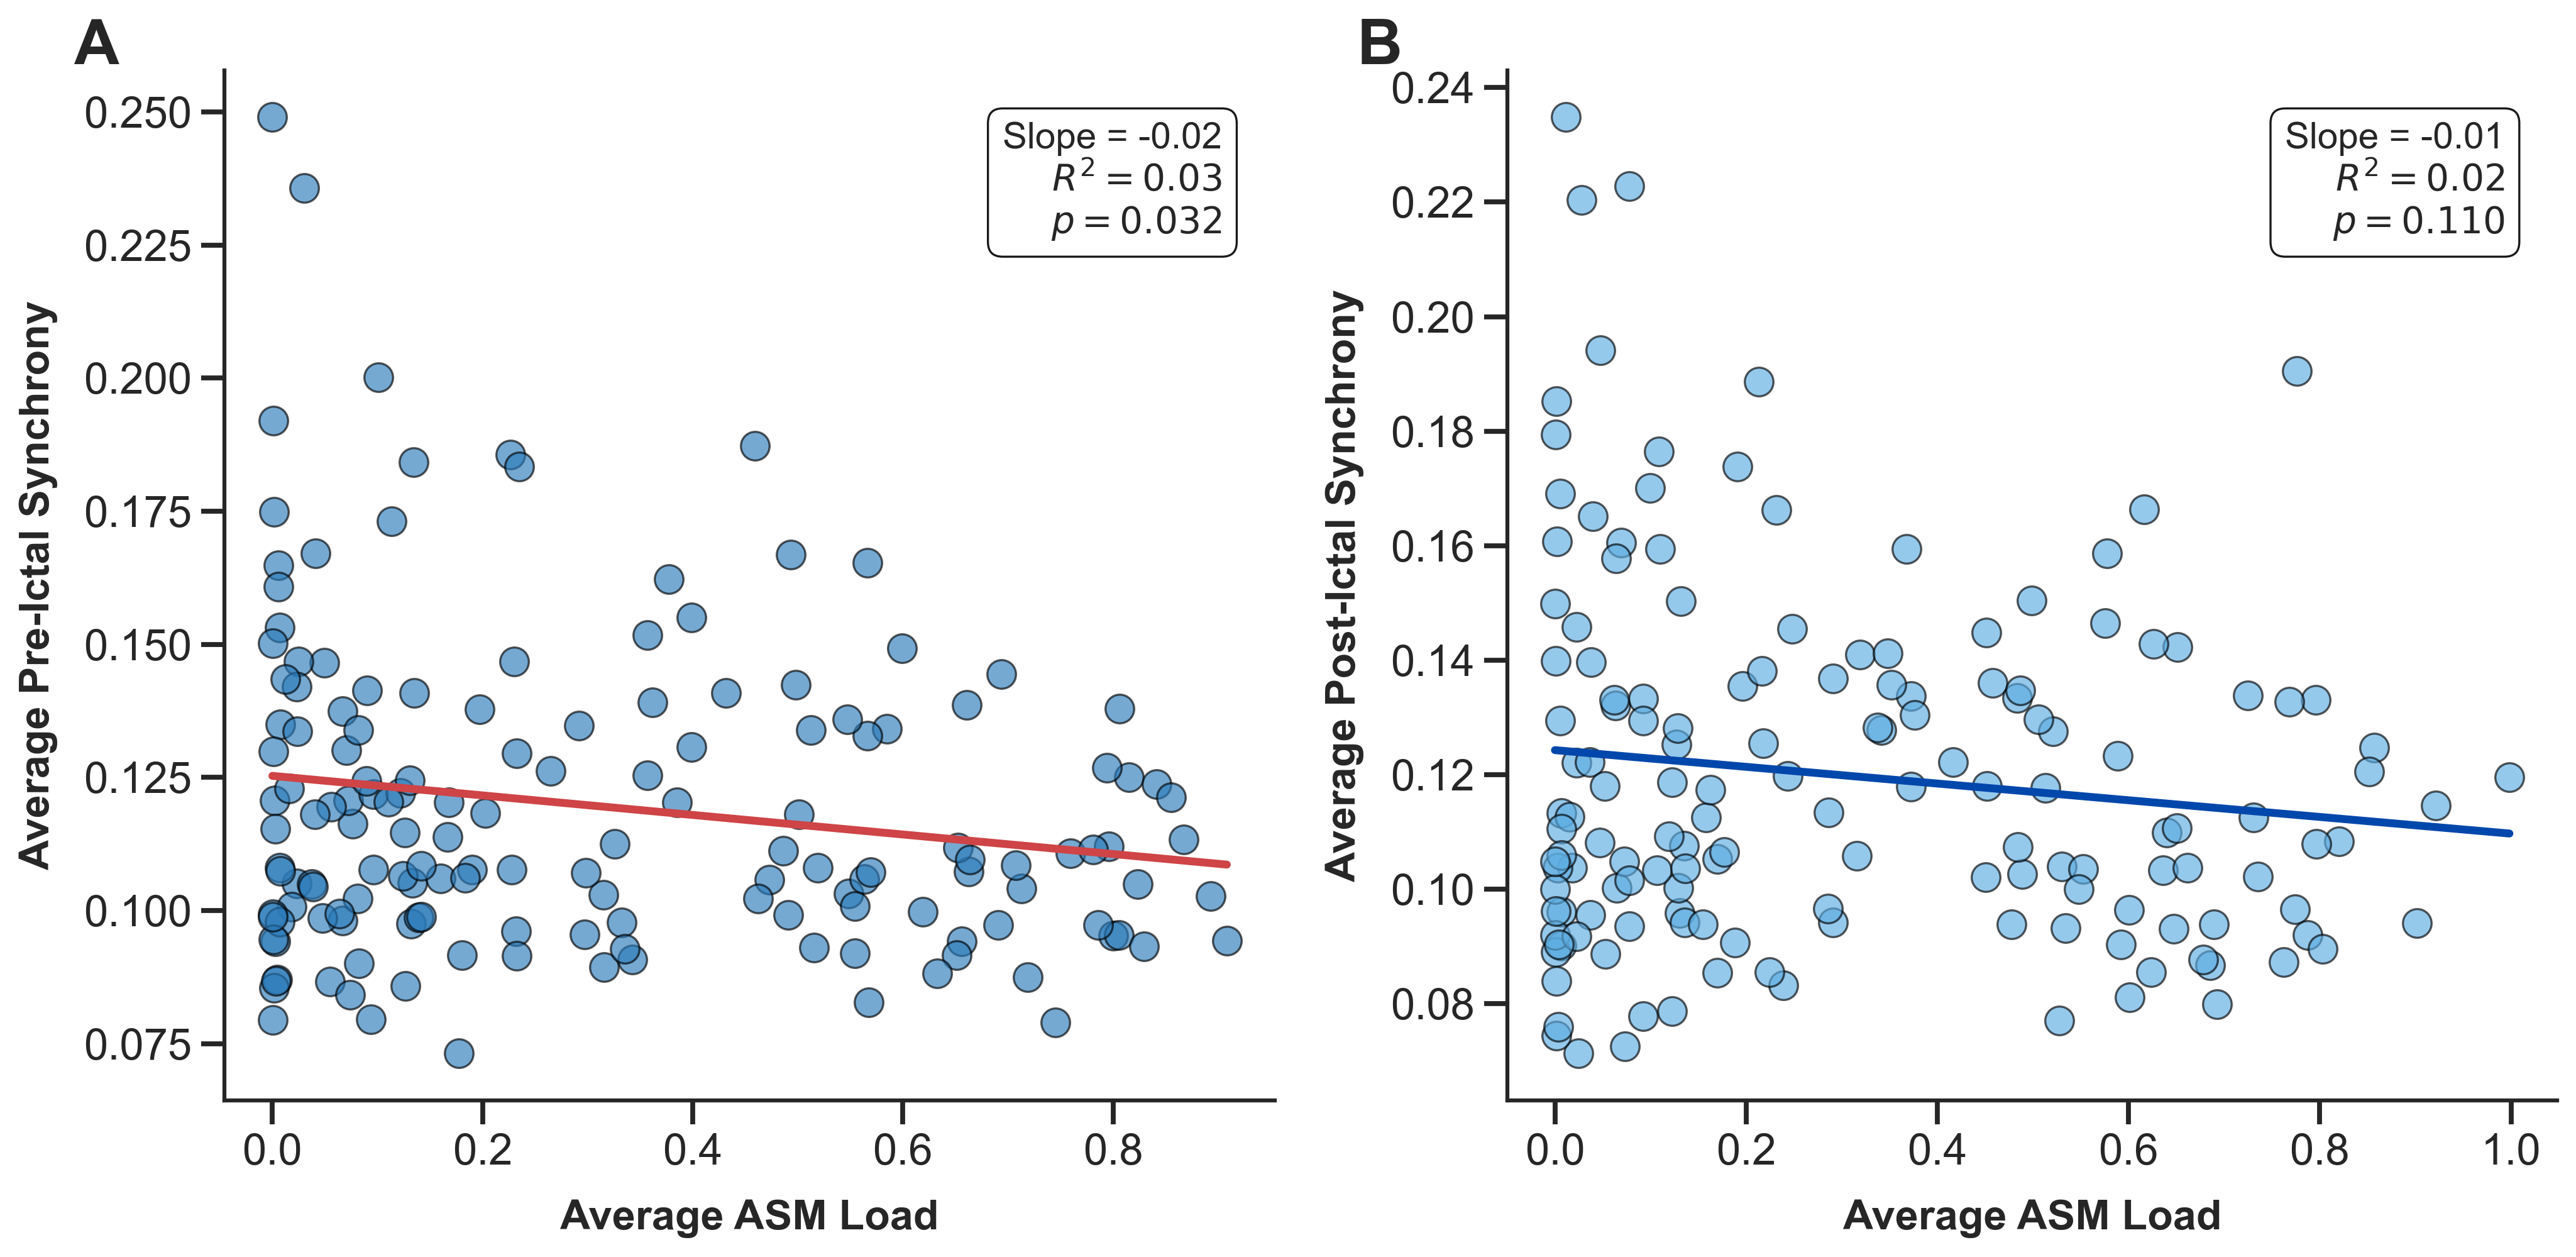

In [2]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

# --- Configuration ---
DATA_PATH = "../../cnt-data/"
TABLES_PATH = os.path.join(DATA_PATH, "giant_new_tables")

# --- Helper Functions ---

def get_patient_hup_ids(directory):
    """Extracts patient IDs from filenames in the directory."""
    files = os.listdir(directory)
    patient_hup_ids = [
        int(f.split("_")[1].split(".")[0]) for f in files if f.startswith("HUP_")
    ]
    return sorted(patient_hup_ids)

def get_pre_ictal_data(hourly_patient_features_df):
    """Analyzes the 60-minute window BEFORE valid seizures."""
    seizure_indices = hourly_patient_features_df[
        hourly_patient_features_df["had_seizure"] >= 1
    ].index

    # Filter for seizures separated by at least 5 hours (300 mins)
    valid_seizure_indices = [
        idx for i, idx in enumerate(seizure_indices)
        if i == 0 or (seizure_indices[i] - seizure_indices[i - 1]) >= 5 * 60
    ]

    seizure_data = []

    for idx in valid_seizure_indices:
        seizure_time = hourly_patient_features_df.loc[idx, "emu_minute"]

        # Window: [Seizure - 60, Seizure)
        window = hourly_patient_features_df[
            (hourly_patient_features_df["emu_minute"] >= seizure_time - 60)
            & (hourly_patient_features_df["emu_minute"] < seizure_time)
        ]
        
        if len(window["synchrony_broadband"]) == 0 or np.all(np.isnan(window["synchrony_broadband"])):
            continue

        avg_synchrony = np.nanmedian(window["synchrony_broadband"])
        avg_med_load = np.nanmedian(window["med_sum_no_lorazepam_raw"])

        if avg_synchrony < 0.8:
            seizure_data.append((avg_med_load, avg_synchrony))

    return seizure_data

def get_post_ictal_data(hourly_patient_features_df):
    """Analyzes the 60-minute window AFTER valid seizures."""
    seizure_indices = hourly_patient_features_df[
        hourly_patient_features_df["had_seizure"] >= 1
    ].index

    valid_seizure_indices = [
        idx for i, idx in enumerate(seizure_indices)
        if i == 0 or (seizure_indices[i] - seizure_indices[i - 1]) >= 5 * 60
    ]

    seizure_data = []

    for idx in valid_seizure_indices:
        seizure_time = hourly_patient_features_df.loc[idx, "emu_minute"]

        # Window: (Seizure, Seizure + 60]
        window = hourly_patient_features_df[
            (hourly_patient_features_df["emu_minute"] > seizure_time)
            & (hourly_patient_features_df["emu_minute"] <= seizure_time + 60)
        ]

        if len(window["synchrony_broadband"]) == 0 or np.all(np.isnan(window["synchrony_broadband"])):
            continue

        avg_synchrony = np.nanmedian(window["synchrony_broadband"])
        avg_med_load = np.nanmedian(window["med_sum_no_lorazepam_raw"])

        if avg_synchrony < 0.8:
            seizure_data.append((avg_med_load, avg_synchrony))

    return seizure_data

def plot_regression_panel(ax, data, y_label, panel_label, point_color, line_color):
    """Helper to calculate stats and draw the regression plot on a specific axis."""
    if not data:
        print(f"No data for panel {panel_label}")
        return

    # Unzip data
    x_vals, y_vals = zip(*data)
    x_list = list(x_vals)
    y_list = list(y_vals)

    # --- Statistics ---
    X = sm.add_constant(x_list)
    model = sm.OLS(y_list, X).fit()
    
    slope = model.params[1]
    r_squared = model.rsquared
    p_value = model.pvalues[1]

    # --- Plotting ---
    sns.regplot(
        x=x_list,
        y=y_list,
        ax=ax,
        scatter_kws={
            "s": 120,
            "alpha": 0.65,
            "edgecolor": "black",
            "linewidths": 0.8,
            "color": point_color
        },
        line_kws={
            "color": line_color,
            "linewidth": 3,
            "label": "Linear Fit"
        },
        ci=None,
    )

    # --- Annotation ---
    stats_text = (
        f"Slope = {slope:.2f}\n"
        f"$R^2 = {r_squared:.2f}$\n"
        f"$p = {p_value:.3f}$"
    )

    ax.text(
        0.95, 0.95, 
        stats_text, 
        transform=ax.transAxes, 
        fontsize=14, 
        verticalalignment='top', 
        horizontalalignment='right',
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="black", linewidth=0.8)
    )

    # --- Formatting ---
    ax.set_xlabel("Average ASM Load", labelpad=10, fontsize=16, fontweight='bold')
    ax.set_ylabel(y_label, labelpad=10, fontsize=16, fontweight='bold')
    
    # Panel Label (A or B)
    ax.text(
        -0.1, 1.05, 
        panel_label, 
        transform=ax.transAxes, 
        fontsize=24, 
        fontweight='bold', 
        va='top', ha='right'
    )

    # Spines
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['left'].set_linewidth(1.5)
    sns.despine(ax=ax)

# --- Main Execution ---

# 1. Load Data
completed_hup_ids = get_patient_hup_ids(TABLES_PATH)
pre_ictal_data = []
post_ictal_data = []

print(f"Processing {len(completed_hup_ids)} patients...")

for patient_hup_id in completed_hup_ids:
    try:
        file_path = os.path.join(TABLES_PATH, f"HUP_{str(patient_hup_id)}.csv")
        df = pd.read_csv(file_path)
        
        # Collect data for both panels in one pass
        pre_ictal_data.extend(get_pre_ictal_data(df))
        post_ictal_data.extend(get_post_ictal_data(df))
        
    except Exception as e:
        print(f"Error processing {patient_hup_id}: {e}")

# 2. Create Figure (1 Row, 2 Columns)
sns.set_theme(style="ticks", context="talk")
fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=300)

# 3. Plot Panel A (Pre-Ictal)
plot_regression_panel(
    ax=axes[0],
    data=pre_ictal_data,
    y_label="Average Pre-Ictal Synchrony",
    panel_label="A",
    point_color="#2b7bba",  # Original color from Panel A
    line_color="#cf4446"
)

# 4. Plot Panel B (Post-Ictal)
plot_regression_panel(
    ax=axes[1],
    data=post_ictal_data,
    y_label="Average Post-Ictal Synchrony",
    panel_label="B",
    point_color="#5DADE2",  # Original color from Panel B
    line_color="#0047AB"
)

plt.tight_layout()
plt.show()